Tugas Machine Learning 7

7.1 Persiapan Library

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, \
    cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,
    precision_score, recall_score, f1_score, roc_curve, auc,
    precision_recall_curve, classification_report)

7.2 Import Dataset

In [ ]:
X, y = make_classification(n_samples=1000, n_features=10,
    weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.3, random_state=42, stratify=y)

7.3 Preprocessing dan Training Model

In [ ]:
model = LogisticRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

7.4 Evaluasi

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-Score :", round(f1_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

# Stratified k-Fold Cross-Validation untuk perbandingan model
skf = StratifiedKFold(n_splits=5, shuffle=True,
    random_state=42)
skor_cv = cross_val_score(model, X, y, cv=skf, scoring="f1")
print("F1-Score tiap fold:", np.round(skor_cv, 3))
print("Rata-rata F1-Score:", round(skor_cv.mean(), 3), "+/-",
    round(skor_cv.std(), 3))

Confusion Matrix:
 [[193  16]
 [ 20  71]]
Precision: 0.816
Recall   : 0.78
F1-Score : 0.798
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       209
           1       0.82      0.78      0.80        91

    accuracy                           0.88       300
   macro avg       0.86      0.85      0.86       300
weighted avg       0.88      0.88      0.88       300

F1-Score tiap fold: [0.821 0.793 0.771 0.807 0.803]
Rata-rata F1-Score: 0.799 +/- 0.017


7.5 Visualisasi

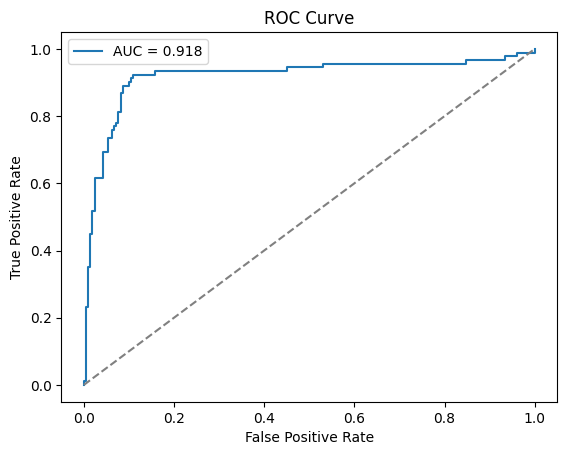

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], '--', color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.show()

7.6 Praktikum 1

Jumlah data : (569, 30)
Distribusi kelas: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}

MODEL: Logistic Regression
Confusion Matrix:
 [[ 63   1]
 [  1 106]]
Precision: 0.991
Recall   : 0.991
F1-Score : 0.991
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171


MODEL: Decision Tree
Confusion Matrix:
 [[ 57   7]
 [  6 101]]
Precision: 0.935
Recall   : 0.944
F1-Score : 0.94
              precision    recall  f1-score   support

   malignant       0.90      0.89      0.90        64
      benign       0.94      0.94      0.94       107

    accuracy                           0.92       171
   macro avg       0.92      0.92      0.92       171
weighted avg       0.92      0.92      0.92       17

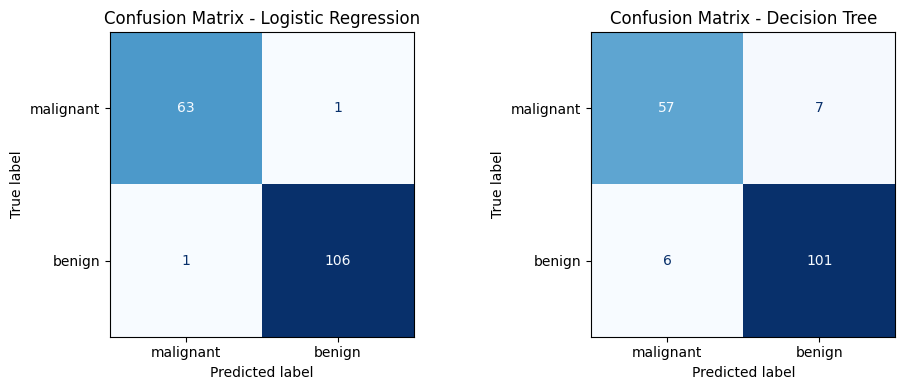

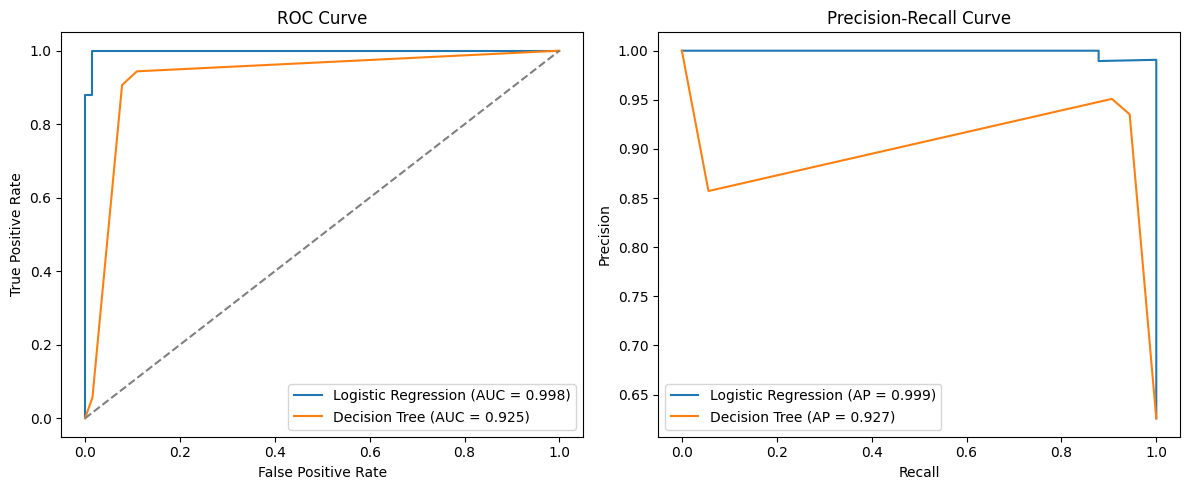


RINGKASAN PERBANDINGAN
Model                  Precision   Recall      F1     AUC
Logistic Regression        0.991    0.991   0.991   0.998
Decision Tree              0.935    0.944   0.940   0.925


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             roc_curve, auc, precision_recall_curve,
                             average_precision_score, classification_report)


data = load_breast_cancer()
X, y = data.data, data.target
print("Jumlah data :", X.shape)
print("Distribusi kelas:", dict(zip(data.target_names, np.bincount(y))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
}

hasil = {}
for nama, mdl in models.items():
    mdl.fit(X_train, y_train)
    y_pred = mdl.predict(X_test)
    y_proba = mdl.predict_proba(X_test)[:, 1]
    hasil[nama] = {"pred": y_pred, "proba": y_proba}

    print("\n" + "=" * 55)
    print("MODEL:", nama)
    print("=" * 55)
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall   :", round(recall_score(y_test, y_pred), 3))
    print("F1-Score :", round(f1_score(y_test, y_pred), 3))
    print(classification_report(y_test, y_pred,
                                target_names=data.target_names))


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nama, h) in zip(axes, hasil.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, h["pred"]),
                           display_labels=data.target_names
                           ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix - {nama}")
plt.tight_layout()
plt.show()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for nama, h in hasil.items():
    fpr, tpr, _ = roc_curve(y_test, h["proba"])
    ax1.plot(fpr, tpr, label=f"{nama} (AUC = {auc(fpr, tpr):.3f})")

    prec, rec, _ = precision_recall_curve(y_test, h["proba"])
    ap = average_precision_score(y_test, h["proba"])
    ax2.plot(rec, prec, label=f"{nama} (AP = {ap:.3f})")

ax1.plot([0, 1], [0, 1], "--", color="gray")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.set_title("ROC Curve")
ax1.legend()

ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_title("Precision-Recall Curve")
ax2.legend()
plt.tight_layout()
plt.show()


print("\nRINGKASAN PERBANDINGAN")
print(f"{'Model':<22}{'Precision':>10}{'Recall':>9}{'F1':>8}{'AUC':>8}")
for nama, h in hasil.items():
    fpr, tpr, _ = roc_curve(y_test, h["proba"])
    print(f"{nama:<22}"
          f"{precision_score(y_test, h['pred']):>10.3f}"
          f"{recall_score(y_test, h['pred']):>9.3f}"
          f"{f1_score(y_test, h['pred']):>8.3f}"
          f"{auc(fpr, tpr):>8.3f}")

7.6 Praktikum 2



STRATIFIED 5-FOLD CROSS-VALIDATION
Model                         accuracy       precision          recall              f1         roc_auc
Logistic Regression       0.974+/-0.017    0.968+/-0.029    0.992+/-0.011    0.979+/-0.013    0.995+/-0.005
   F1 tiap fold: [0.979 0.959 0.973 0.993 0.993]
Decision Tree             0.923+/-0.030    0.928+/-0.039    0.952+/-0.026    0.939+/-0.022    0.915+/-0.037
   F1 tiap fold: [0.965 0.898 0.94  0.943 0.952]
Random Forest             0.954+/-0.010    0.962+/-0.028    0.966+/-0.027    0.964+/-0.008    0.990+/-0.008
   F1 tiap fold: [0.971 0.952 0.966 0.957 0.972]


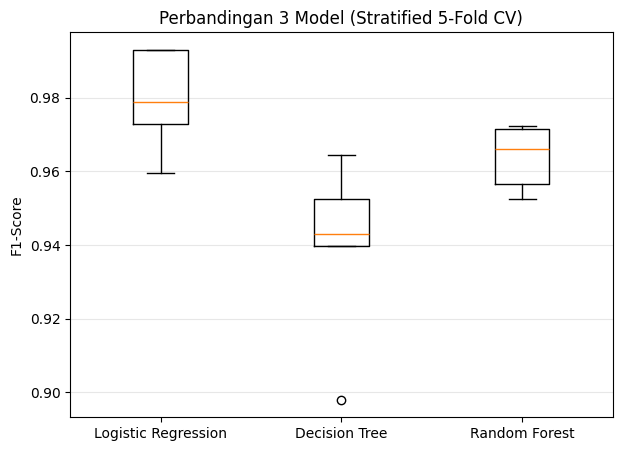


Model terbaik berdasarkan rata-rata F1: Logistic Regression (0.979)


In [ ]:
models_cv = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200,
                                            random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrik = ["accuracy", "precision", "recall", "f1", "roc_auc"]

print("\n\nSTRATIFIED 5-FOLD CROSS-VALIDATION")
print(f"{'Model':<22}" + "".join(f"{m:>16}" for m in metrik))
skor_f1 = {}
for nama, mdl in models_cv.items():
    cv = cross_validate(mdl, X, y, cv=skf, scoring=metrik)
    skor_f1[nama] = cv["test_f1"]
    baris = "".join(
        f"{cv['test_' + m].mean():>9.3f}+/-{cv['test_' + m].std():.3f}"
        for m in metrik)
    print(f"{nama:<22}{baris}")
    print("   F1 tiap fold:", np.round(cv["test_f1"], 3))


plt.figure(figsize=(7, 5))
plt.boxplot(list(skor_f1.values()))
plt.xticks(range(1, len(skor_f1) + 1), list(skor_f1.keys()))
plt.ylabel("F1-Score")
plt.title("Perbandingan 3 Model (Stratified 5-Fold CV)")
plt.grid(axis="y", alpha=0.3)
plt.show()

terbaik = max(skor_f1, key=lambda k: skor_f1[k].mean())
print(f"\nModel terbaik berdasarkan rata-rata F1: {terbaik} "
      f"({skor_f1[terbaik].mean():.3f})")

7.6 Praktikum

In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

X, y = make_classification(n_samples=1000, n_features=10,
    weights=[0.7, 0.3], random_state=42)

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

model_list = {"Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(max_depth=5,
    random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5), }
skf = StratifiedKFold(n_splits=5, shuffle=True,
    random_state=42)
hasil = {}
for nama, model in model_list.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1")
    hasil[nama] = skor
    print(f"{nama}: F1 rata-rata = {skor.mean():.3f} "
          f"(+/- {skor.std():.3f})")

terbaik = max(hasil, key=lambda k: hasil[k].mean())
stabil = min(hasil, key=lambda k: hasil[k].std())
print(f"\nKesimpulan:")
print(f"- Paling baik  : {terbaik} (F1 rata-rata {hasil[terbaik].mean():.3f})")
print(f"- Paling stabil: {stabil} (std {hasil[stabil].std():.3f})")

Logistic Regression: F1 rata-rata = 0.799 (+/- 0.017)
Decision Tree: F1 rata-rata = 0.854 (+/- 0.034)
KNN: F1 rata-rata = 0.769 (+/- 0.042)

Kesimpulan:
- Paling baik  : Decision Tree (F1 rata-rata 0.854)
- Paling stabil: Logistic Regression (std 0.017)
